# Shifting the charging of Utrecht's electric buses away from the grid peak

**TIL6022 TIL Python Programming · Group 22 · TU Delft, 2026/27**

Daniël Oosterink ([@doosterink](https://github.com/doosterink)) ·
Nick Wong ([@nwtud](https://github.com/nwtud)) ·
Shubham Behera ([@shubham5behera](https://github.com/shubham5behera)) ·
Rakesh Chandrikasing ([@rchandrikasing](https://github.com/rchandrikasing))

**Contents**
1. Introduction and research question
2. Contribution statement
3. Data analysis pipeline
4. Results
5. Discussion
6. Conclusion
7. Use of generative AI and sources

# 1. Introduction and research question

The city buses of Utrecht run on batteries and are charged at three depots: **Westraven**, **Nieuwegein Remiseweg** and
**Lage Weide**. The regional electricity grid around these depots is congested: the capacity map of Netbeheer
Nederland lists, for each of the three supply areas, parties that are waiting for a new or larger connection (the
queue). The demand on the grid is highest in the late afternoon and early evening; in the areas studied here the peak
falls between 16:00 and 20:00 (section 4.4). Many buses return to their depot in exactly that period and are plugged
in straight away. Their charging then competes with the households and companies that were already using the grid.

If the charging can be moved to quieter hours, more room is left for those original users, as long as every bus is
still charged in time for its next service.

**Research question**

> *How can the charging of Utrecht's electric buses be shifted to other moments, so that the original users of the grid
> around the bus depots are not restricted in their electricity use?*

This question is narrower than the one in our research proposal
([TIL6022_Group22_proposal.pdf](TIL6022_Group22_proposal.pdf)). After the midterm presentation we focused on the grid
around the three depots and the room left for its existing users, because no local household load data were available.

**Sub-questions**
1. How much capacity is left in the grid around each depot, once the parties in the queue are included?
2. How much energy do the buses of each depot need, and when is it charged today?
3. Which charging strategy keeps the charging out of the busy hours while every bus is still charged, and how much room
   does that give back to the other users?

# 2. Contribution statement

| Member | Contribution |
|:--|:--|
| Daniël Oosterink | Coding; bus data (lines, fleet, energy use) and the bus line–depot assignment script; grid data; external communication (e.g. contact with Transdev) |
| Nick Wong | Coding; building the data pipelines |
| Rakesh Chandrikasing | Grid data on network congestion and capacity per supply area; external communication; README and repository |
| Shubham Behera | Modelling the data pipelines; data analysis; coding and debugging |

All four members coordinated their parts with each other, discussed the results together and contributed to this
report. Most of the work was done simultaneously in a shared Google Drive folder (Google Colab notebooks and data
files); the final versions were then committed to this GitHub repository by the members who made them.

# 3. Data analysis pipeline

The analysis combines two pipelines. The **bus pipeline** calculates how much energy the buses of each depot need;
it is in `Script busline remise assignment with comments.ipynb`. The **grid pipeline** calculates, for every hour of the
year, how much room is left in the grid around each depot; it is in the notebooks `notebooks/00` to `notebooks/07`.
The two meet in the last step, where the charging of the buses is placed on top of the grid load.

## 3.1 Bus data

For the data of the buses, the following datasets and sources were used:

* GTFS data from Stichting OpenGeo from the website <https://gtfs.ovapi.nl/>. The data requires data processing before
  being able to be used in the project. The files with the data about routes, shapes, trips and stopping times were
  combined using a Python script, so that the length, duration and number of trips can be obtained. Also, as only buses
  from the concession Utrecht Binnen are considered, all other buses are removed. This results in one dataframe with all
  bus lines in Utrecht Binnen. For convenience, this file was exported to a spreadsheet file.
* Data from bus manufacturers regarding battery capacity. In addition, independent tests were consulted to calculate
  efficiency, which is used to determine energy consumption per kilometre.
* The website of OV in Nederland Wiki (<https://wiki.ovinnederland.nl/>) provides detailed information about the bus
  fleet in the concession Utrecht Binnen (how many buses there are of every model and which models are used on every
  line), and the frequency of bus lines during the peak hour. Also, it has information about the locations of the bus
  depots.

The following steps were taken to calculate the energy consumption per bus and the needed energy consumption per bus
depot:

1. In the Excel file with the GTFS data, the peak frequency is added. Then, the minimal number of buses used during the
   peak hour (the governing situation) can be calculated by multiplying the peak frequency (per hour) with the average
   time to drive the whole route.
2. To determine which bus depot will be used, for each line, the distance from a bus depot to the starting point and
   the distance from the end point back to the bus depot was calculated. The bus depot with the shortest sum of these
   two distances is the bus depot that will be used.
3. Bus models are assigned to the bus lines. It is known which models are used on every line; however, it is not known
   what the ratio between the use of different bus models is. Lines that use only one model get that model first. The
   remaining buses are divided over the other lines with an integer optimisation (MILP, `scipy`) that first minimises
   the number of buses missing on any line, within the number of buses available per model.
4. The energy consumption per bus can be calculated by multiplying the average distance and the energy consumption per
   km, plus the distance to drive from and to the bus depot. The latter can be calculated using how often a bus has to
   be charged, which in turn is calculated using the energy consumption. Using iteration, the number of charging cycles
   can be calculated.
5. Finally, the energy per depot is spread over the night (22:00–06:00) and compared with the grid connection of the
   depot and with the hourly grid data of the supply area (datasets 1, 2 and 4 of the grid pipeline).

## 3.2 Grid data

For the grid around the depots, three open sources are used. Python reads each of them directly from the web and
filters it in memory; when a source is offline, a stored copy in `data/backup` is used instead. Which source was used
for every dataset is logged in `data/interim/0_data_provenance.csv`.

* **Netbeheer Nederland capacity map** (<https://capaciteitskaart.netbeheernederland.nl/>), file `voedingsgebieden.csv`:
  for about 600 supply areas (*voedingsgebieden*) in 2026 the present transport capacity, the capacity required at the
  peak moment and the capacity requested by parties on the waiting list (the queue), all for offtake in MW.
* **Netbeheer Nederland postcode file** (`congestie_pc6.csv`) together with **OpenStreetMap Nominatim**: used to find
  the supply area that feeds each depot.
* **ENTSO-E national load of the Netherlands**, 2025, via the Energy-Charts API (<https://api.energy-charts.info/>):
  electricity demand of the whole country in 15-minute steps.

The following steps were taken to obtain the room that is left in the grid for every hour of the year:

1. **Depots to supply areas.** Remiseweg and Westraven are geocoded and linked to their supply area through their
   six-digit postcode: CM10 Oudenrijn and CM39 Nieuwegein. Lage Weide is linked to CM60 Utrecht Lage Weide by the name
   of the area; its postcode is only checked when notebook 01 runs online.
2. **Filtering the capacity file.** The national file is reduced step by step:
   all areas (602) → grid operator Stedin (244) → province of Utrecht (47) → the three depot areas (3).
   A blank value means that the operator did not publish a figure; it is never read as zero.
3. **Estimating CM39.** No capacity is published for Westraven's area, so it is scaled from Oudenrijn by the number of
   postcodes:
   $$C_{CM39} = 3287 \cdot \frac{45\ \text{MW}}{1048} \approx 141\ \text{MW} \quad (\text{range } 99\text{–}205\ \text{MW}),
   \qquad P_{CM39} = 0.92 \cdot C_{CM39}$$
   where 0.92 is the median ratio of peak to capacity of the Utrecht areas for which both figures are published.
4. **Hourly national load.** The 15-minute values are averaged to hourly values in local time (Europe/Amsterdam). On
   the day the clocks go forward, the missing hour is filled by linear interpolation; on the day they go back, the
   hour that occurs twice is averaged. If the API is unavailable, the hourly series is rebuilt from stored daily totals
   $E_d$ and an hourly profile $p_{m,k,h}$ per month $m$ and day type $k$:
   $$L_{NL}(d,h) = E_d \cdot \frac{p_{m,k,h}}{\sum_{h'} p_{m,k,h'}}$$
5. **Load per supply area.** No hourly load is published per supply area, so the national pattern is scaled to the
   published peak $P_a$ of each area:
   $$L_a(t) = L_{NL}(t) \cdot \frac{P_a}{\max_t L_{NL}(t)}$$
6. **Bus charging.** The energy per depot is turned into a charging profile in 15-minute steps, using the arrival
   times of the buses from the timetable, for four strategies:
   S1 charging on arrival, S2 no charging 16:00–20:00, S3 spread over 22:00–06:00 and S4 grid-aware charging. Because the
   published peak already contains today's charging, the S1 profile is first subtracted to obtain the area load without
   the depot, $L_{a,\text{excl}}(t)$, and each strategy $B_a(t)$ is then added back.
7. **Comparison with capacity.** For every hour the remaining room and the planning view including the queue $Q_a$ are
   $$R_a(t) = C_a - L_{a,\text{excl}}(t) - B_a(t), \qquad U_a = \frac{P_a + Q_a}{C_a}$$
   A value of $U_a$ above 100% means that the capacity is fully taken once the waiting parties are connected.

## 3.3 Datasets produced by the pipeline

The cell below loads the datasets that the pipeline writes to `data/processed` and the log of which source was used
for each input. All results in section 4 are calculated from these files.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = Path('data/processed')

# readable names for the tables shown in this report
LABELS = {'bus_depot': 'depot', 'supply_area': 'supply area', 'capacity_basis': 'capacity basis',
          'capacity_MW': 'capacity (MW)', 'peak_MW': 'peak (MW)', 'queue_MW': 'queue (MW)',
          'used_plus_queue_pct': 'used + queue (%)', 'peak_share_pct': 'used at peak, no queue (%)',
          'short_incl_queue_MW': 'short incl. queue (MW)', 'service_km_weekday': 'service km / weekday',
          'empty_km_weekday': 'empty km / weekday', 'kWh_per_km_avg': 'kWh per km', 'MWh_weekday': 'MWh / weekday',
          'share_energy_16_20_pct': 'charged 16-20 h (%)', 'depot_peak_MW': 'depot peak S1 (MW)',
          'depot_at_area_peak_MW': 'depot load at area peak (MW)', 'bus_load_at_area_peak_MW': 'bus load at area peak (MW)',
          'after_shift_pct': 'after shifting (%)', 'after_shift_upper_bound_pct': 'after shifting, upper bound (%)',
          'min_night_room_MW': 'min. room at night (MW)', 'connection_MW': 'connection (MW)',
          'depot_peak_S3_MW': 'S3 night peak (MW)', 'night_S3_fits_connection': 'S3 fits connection',
          'night_S3_fits_grid': 'S3 fits grid', 'full_battery_in_8h_MW': 'worst case: full battery in 8 h (MW)',
          'worst_case_fits_connection': 'worst case fits connection'}
show = lambda df: df.rename(columns=LABELS).rename_axis(index=LABELS.get(df.index.name, df.index.name))

d1 = pd.read_csv(PROCESSED/'1_Depot_and_Grid_Supply_Area_Data.csv')    # depots and their supply areas
d2 = pd.read_csv(PROCESSED/'2_Grid_Capacity_and_Congestion_Data.csv')  # capacity, peak and queue per area
d3 = pd.read_csv(PROCESSED/'3_Hourly_Grid_Load_Data.csv')              # hourly load per area (8,760 h)
d4 = pd.read_csv(PROCESSED/'4_Bus_Charging_and_Grid_Comparison.csv')   # grid load + charging per strategy
d4a = pd.read_csv(PROCESSED/'4a_Bus_Energy_per_Depot.csv')             # bus energy per depot
kpi = pd.read_csv(PROCESSED/'4b_Scenario_KPIs.csv')                     # key figures per strategy
res = pd.read_csv(PROCESSED/'8_Results_per_Depot.csv')                  # summary per depot (notebook 07)

overview = pd.DataFrame({
    'dataset': ['1 depots and supply areas', '2 capacity and congestion', '3 hourly grid load',
                '4 charging and grid comparison', '4a bus energy per depot'],
    'rows': [len(d1), len(d2), len(d3), len(d4), len(d4a)],
    'columns': [d1.shape[1], d2.shape[1], d3.shape[1], d4.shape[1], d4a.shape[1]]})
display(overview)

provenance = pd.read_csv('data/interim/0_data_provenance.csv')         # which source was used for each input
provenance[['step', 'dataset', 'used', 'source']]

,dataset,rows,columns
0,1 depots and supply areas,3,17
1,2 capacity and congestion,51,13
2,3 hourly grid load,26280,13
3,4 charging and grid comparison,26280,27
4,4a bus energy per depot,3,17


,step,dataset,used,source
0,1,depot coordinates,raw,"data/raw/bus_team (Nominatim, earlier run by t..."
1,1,postcode -> supply area,backup,data/backup/capaciteitskaart_postcode_lookup.csv
2,2,capacity per supply area,backup,data/backup/netbeheer_voedingsgebieden_2026.csv
3,2,planned projects,raw,data/raw/stroomindex_area_info.csv
4,3,national hourly load 2025,backup,data/backup/national_load_NL_2025_daily_totals...
5,3b,national hourly load per year,backup,step 3 series (data/interim/3_national_load_us...
6,4,GTFS timetable (U-OV trips),backup,data/backup/gtfs_subset/


# 4. Results

## 4.1 How full is the grid around each depot?

The capacity map gives three numbers per supply area: the capacity, the load at the peak moment and the capacity that
waiting parties have asked for. The planning view adds the queue to the peak:

$$U_a = \frac{P_a + Q_a}{C_a}$$

Above 100%, the waiting parties cannot all be connected; every MW that the buses use at the peak is then a MW that a
waiting household or company cannot get.

In [2]:
grid = res[['bus_depot', 'supply_area', 'capacity_basis', 'capacity_MW', 'peak_MW', 'queue_MW',
            'used_plus_queue_pct']].copy()
grid['peak_share_pct'] = (100 * grid['peak_MW'] / grid['capacity_MW']).round(1)   # without the queue
grid['short_incl_queue_MW'] = (grid['peak_MW'] + grid['queue_MW'] - grid['capacity_MW']).round(1)
show(grid.set_index('bus_depot'))

,supply area,capacity basis,capacity (MW),peak (MW),queue (MW),used + queue (%),"used at peak, no queue (%)",short incl. queue (MW)
depot,,,,,,,,
Nieuwegein - Remiseweg,CM10,OBSERVED,45.0,39.07,6.01,100.2,86.8,0.1
Utrecht - Lage Weide,CM60,OBSERVED,360.0,310.80,28.07,94.1,86.3,-21.1
Utrecht - Westraven,CM39,ASSUMED,141.1,129.80,48.76,126.5,92.0,37.5


Without the queue, all three areas still have room at their peak (86–92% used). With the queue included, the
picture changes: Lage Weide keeps room (94%), Remiseweg is just full (100.2%) and Westraven is far over its capacity
(126.5%, 37.5 MW short). Westraven's capacity is an estimate (see section 3.2 and the Discussion).

## 4.2 How much energy do the buses need and when?

The bus pipeline gives the number of buses, the kilometres and the energy per depot. In the reference situation (S1)
each bus starts charging as soon as it arrives.

*Note:* the grid notebooks use the energy per depot from the bus team's line–depot file (197, 57 and 54 buses). The
final bus script assigns 190, 56 and 47 buses, because not every line can be served by the available fleet (see the
Discussion). The energy per depot follows from the kilometres driven on the lines and the energy use per km, so it
hardly depends on this difference in bus numbers.

In [3]:
energy = d4a[['bus_depot', 'lines', 'buses', 'service_km_weekday', 'empty_km_weekday', 'kWh_weekday',
              'kWh_per_km_avg']].copy()
energy['MWh_weekday'] = (energy['kWh_weekday'] / 1000).round(1)
s1 = kpi[(kpi['period'] == 'year') & (kpi['scenario'] == 'S1')].set_index('bus_depot')
energy = energy.set_index('bus_depot').join(s1[['share_energy_16_20_pct', 'depot_peak_MW', 'depot_at_area_peak_MW']])
show(energy.drop(columns='kWh_weekday').round({'service_km_weekday': 0, 'empty_km_weekday': 0, 'depot_peak_MW': 2,
                                               'depot_at_area_peak_MW': 2}))

,lines,buses,service km / weekday,empty km / weekday,kWh per km,MWh / weekday,charged 16-20 h (%),depot peak S1 (MW),depot load at area peak (MW)
depot,,,,,,,,,
Utrecht - Lage Weide,12,54,8665.0,834.0,1.163,11.9,15.5,1.46,0.30
Nieuwegein - Remiseweg,12,57,10915.0,1255.0,1.315,17.3,12.5,2.12,0.32
Utrecht - Westraven,25,197,26114.0,4246.0,1.532,50.2,14.2,6.09,1.11


With charging on arrival, 12–16% of the bus energy is charged between 16:00 and 20:00. At the moment of the area
peak the depots draw 0.3 MW (Remiseweg, Lage Weide) to 1.1 MW (Westraven), which is less than 1% of the area peak.

## 4.3 Charging strategies

Four strategies are compared for every hour of the year:
- **S1 Reference:** charging starts at full power on arrival.
- **S2 Pause in the peak:** no charging from 16:00 to 20:00, full power afterwards.
- **S3 Night charging:** the charging is spread as evenly as possible over 22:00–06:00.
- **S4 Grid-aware:** no charging in the evening peak, the area peak is never raised and the depot load is kept flat.

,depot peak S1 (MW),depot peak S2 (MW),depot peak S3 (MW),depot peak S4 (MW),connection (MW),S2 vs S1 (%),S4 vs S1 (%)
depot,,,,,,,
Nieuwegein - Remiseweg,2.12,3.17,2.20,1.44,3.89,50.0,-32.0
Utrecht - Lage Weide,1.46,2.34,1.47,0.85,3.70,60.0,-42.0
Utrecht - Westraven,6.09,9.01,6.29,4.02,9.50,48.0,-34.0


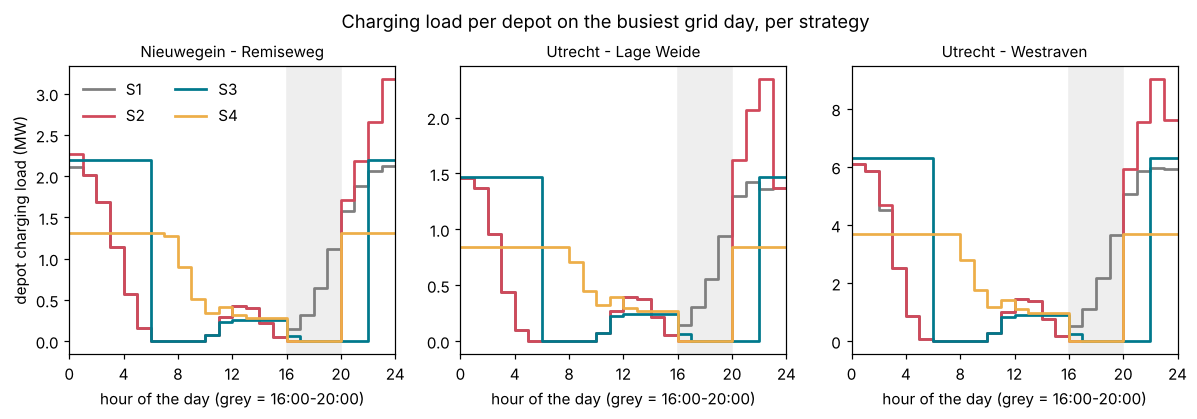

In [4]:
year = kpi[kpi['period'] == 'year']
peaks = year.pivot(index='bus_depot', columns='scenario', values='depot_peak_MW').round(2)
peaks.columns = [f'depot peak {c} (MW)' for c in peaks.columns]
peaks['connection (MW)'] = res.set_index('bus_depot')['connection_MW']
peaks['S2 vs S1 (%)'] = (100 * (peaks['depot peak S2 (MW)'] / peaks['depot peak S1 (MW)'] - 1)).round(0)
peaks['S4 vs S1 (%)'] = (100 * (peaks['depot peak S4 (MW)'] / peaks['depot peak S1 (MW)'] - 1)).round(0)
display(show(peaks))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=False)
colors = {'S1': '#7f7f7f', 'S2': '#d1495b', 'S3': '#00798c', 'S4': '#edae49'}
day = d4[d4['date'] == d3.loc[d3['national_load_MW'].idxmax(), 'date']]          # busiest grid day of the year
for ax, (dep, g) in zip(axes, day.groupby('bus_depot')):
    g = g.sort_values('hour_start')
    for s, c in colors.items():
        y = g[f'depot_{s}_MW'].tolist()
        ax.step(g['hour_start'].tolist() + [24], y + y[-1:], where='post', color=c, label=s, lw=1.8)  # last hour up to 24:00
    ax.axvspan(16, 20, color='#eeeeee', zorder=0)
    ax.set_title(dep, fontsize=10); ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 4))
    ax.set_xlabel('hour of the day (grey = 16:00-20:00)')
axes[0].set_ylabel('depot charging load (MW)'); axes[0].legend(frameon=False, ncol=2)
_ = fig.suptitle('Charging load per depot on the busiest grid day, per strategy', y=1.03)

Only pausing in the peak (S2) does not work well: the buses that waited during the pause start charging after 20:00,
on top of the buses that arrive later in the evening. This raises the depot's own peak by 48–60% (Westraven: 9.0 MW, 95% of its connection). Night charging (S3) keeps the depot peak almost the same
as today, and grid-aware charging (S4) lowers it by 32–42%. S3 and S4 both take (almost) all charging out of 16:00–20:00 and
charge every bus in time (no unmet energy).

## 4.4 What does shifting give back to the other users?

When the charging leaves the evening, the area peak drops by the bus load at the peak hour. The planning view after
shifting is therefore

$$U_a^{\text{shift}} = \frac{P_a + Q_a - B_a(t_{\text{peak}})}{C_a}$$

Notebook 07 also gives an upper bound, in which the highest bus load between 16:00 and 20:00 is removed instead.

In [5]:
shift = res.set_index('bus_depot')[['capacity_MW', 'peak_MW', 'queue_MW', 'used_plus_queue_pct',
                                     'bus_load_at_area_peak_MW', 'freed_by_shift_MW']].copy()
shift['after_shift_pct'] = (100 * (shift['peak_MW'] + shift['queue_MW'] - shift['bus_load_at_area_peak_MW'])
                            / shift['capacity_MW']).round(1)
shift['after_shift_upper_bound_pct'] = (100 * (shift['peak_MW'] + shift['queue_MW'] - shift['freed_by_shift_MW'])
                                        / shift['capacity_MW']).round(1)
display(show(shift[['used_plus_queue_pct', 'bus_load_at_area_peak_MW', 'after_shift_pct', 'after_shift_upper_bound_pct']]))

peak_day = pd.read_csv(PROCESSED/'8b_Peak_Day_Load_Queue_Capacity.csv')
hours_over = peak_day.groupby('bus_depot').apply(lambda g: pd.Series({
    'hours >100% today (S1)': int((g['utilisation_S1_incl_queue_pct'] > 100).sum()),
    'hours >100% night charging (S3)': int((g['utilisation_S3_incl_queue_pct'] > 100).sum()),
    'highest % today (S1)': g['utilisation_S1_incl_queue_pct'].max(),
    'highest % night charging (S3)': g['utilisation_S3_incl_queue_pct'].max()}), include_groups=False)
hours_over = hours_over.astype({'hours >100% today (S1)': int, 'hours >100% night charging (S3)': int})
show(hours_over)

,used + queue (%),bus load at area peak (MW),after shifting (%),"after shifting, upper bound (%)"
depot,,,,
Nieuwegein - Remiseweg,100.2,0.32,99.5,97.7
Utrecht - Lage Weide,94.1,0.30,94.0,93.9
Utrecht - Westraven,126.5,1.11,125.8,124.0


,hours >100% today (S1),hours >100% night charging (S3),highest % today (S1),highest % night charging (S3)
depot,,,,
Nieuwegein - Remiseweg,1,0,100.2,99.5
Utrecht - Lage Weide,0,0,94.1,94.0
Utrecht - Westraven,18,19,126.5,125.8


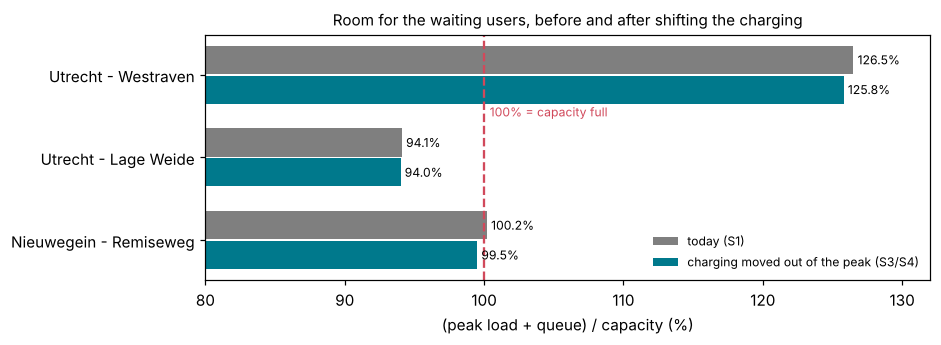

In [6]:
# key result: peak load + queue as a share of capacity, today and after moving the charging out of the peak
fig, ax = plt.subplots(figsize=(8.5, 2.9))
y = np.arange(len(shift))
ax.barh(y + 0.18, shift['used_plus_queue_pct'], height=0.34, color='#7f7f7f', label='today (S1)')
ax.barh(y - 0.18, shift['after_shift_pct'], height=0.34, color='#00798c', label='charging moved out of the peak (S3/S4)')
for i, (a, b) in enumerate(zip(shift['used_plus_queue_pct'], shift['after_shift_pct'])):
    ax.text(a + 0.3, i + 0.18, f'{a:.1f}%', va='center', fontsize=8)
    ax.text(b + 0.3, i - 0.18, f'{b:.1f}%', va='center', fontsize=8)
ax.axvline(100, color='#d1495b', lw=1.5, ls='--')
ax.text(100.4, 1.55, '100% = capacity full', color='#d1495b', fontsize=8, va='center')
ax.set_yticks(y, shift.index); ax.set_xlim(80, 132)
ax.set_xlabel('(peak load + queue) / capacity (%)')
ax.legend(frameon=False, loc='lower right', fontsize=8)
_ = ax.set_title('Room for the waiting users, before and after shifting the charging', fontsize=10)

![Peak day per depot](figures/07_peak_day_load_queue_capacity.png)

*Figure: load, load plus queue and capacity per supply area on the busiest grid day (27 November 2025).*

- **Remiseweg:** on the peak day the limit is only passed in one hour (17:00, 100.2%). With night charging this hour
  disappears (99.5%); the waiting parties then fit.
- **Lage Weide:** there is room all day (at most 94.1%), with or without shifting.
- **Westraven:** including the queue, the limit is passed from 06:00 to midnight. Shifting lowers the peak only from
  126.5% to 125.8%; the shortage of 37.5 MW is more than thirty times the bus load at the peak. Because the queue is
  so large, night charging even adds one extra hour above 100% at 05:00.

## 4.5 Does charging at night fit?

Two checks are made: the room in the grid at night, and the depot's own grid connection.

In [7]:
night = res.set_index('bus_depot')[['min_night_room_MW', 'connection_MW', 'depot_peak_S3_MW',
                                     'night_S3_fits_connection', 'night_S3_fits_grid']].copy()
# worst case from the bus script: every battery from empty to full in 8 hours (22:00-06:00)
night['full_battery_in_8h_MW'] = pd.Series({'Utrecht - Westraven': 10.72, 'Nieuwegein - Remiseweg': 3.36,
                                            'Utrecht - Lage Weide': 2.48})
night['worst_case_fits_connection'] = night['full_battery_in_8h_MW'] <= night['connection_MW']
show(night)

,min. room at night (MW),connection (MW),S3 night peak (MW),S3 fits connection,S3 fits grid,worst case: full battery in 8 h (MW),worst case fits connection
depot,,,,,,,
Nieuwegein - Remiseweg,16.16,3.89,2.20,True,True,3.36,True
Utrecht - Lage Weide,115.57,3.70,1.47,True,True,2.48,True
Utrecht - Westraven,44.42,9.50,6.29,True,True,10.72,False


Without the queue, at least 16 MW (Remiseweg), 44 MW (Westraven) and 116 MW (Lage Weide) is free at night, so the
grid can take the night charging. With the energy the buses really use per day, the night charging (S3) also stays
within each depot's connection. In the worst case of the bus script, where every battery is charged from empty to full
in eight hours, Westraven needs 10.7 MW, more than its 9.5 MW connection; Remiseweg and Lage Weide still fit.

# 5. Discussion

This study makes many assumptions because (exact) data is not always available.

For the buses, their routes and battery capacity, the following assumptions were made:

* The bus demand is based on one representative weekday from the timetable.
* Some routes are served by multiple bus models. The usage ratio among the different models is unknown; Transdev had
  been contacted, but there was no response. Therefore, they have been allocated with the optimisation described in
  section 3.1.
* When assigning bus routes to bus depots, the distance from the depot to the route's starting point and from the
  route's ending point to the depot was used. However, it is possible that a particular route uses a different bus
  depot, for example, because a depot's capacity is insufficient.
* For the battery capacity of some of the buses, information provided by the manufacturer was used. However, the
  manufacturer has an interest in presenting the capacity in a more favourable light than it actually is. This study
  assumes that the capacity, as specified by the manufacturer, is entirely accurate. Energy use per km comes from
  independent tests or, if these are missing, from manufacturer data.
* Not all buses are able to complete their full route on one battery charge. As there is no public, accurate
  information about congestion during the day, it is assumed that the 54 buses that need extra energy can charge during
  the day.

For the grid capacity, the following assumptions were made, because no measured local load or operator data were
available:

* **Grid capacity:** the Netbeheer Nederland capacity map data (2026) are correct, and "required transport capacity" is
  the load at the peak moment. Each depot is fed from its own supply area.
* **Westraven (CM39):** no offtake capacity or peak is published (the queue is), so the capacity is scaled from Oudenrijn by the number of
  postcodes (141 MW, range 99–205 MW) and the peak is 0.92 × capacity, the median of comparable Stedin areas.
* **Lage Weide:** treated as a Transdev depot (Protonweg 13), although this is not confirmed. It is linked to supply
  area CM60 by the area's name, without a full-postcode check. Its grid connection (3.9 MVA) is not published and is
  scaled from Westraven (71.4 kVA per bus). CM60 is an industrial estate, so its real daily load pattern probably
  differs from the national pattern used here. The capacity, peak and queue of CM60 themselves are published values.
* **Hourly load:** each area follows the national ENTSO-E load pattern of 2025, scaled to its published peak, with no
  growth to 2026. The published peak already includes the depots' current charging.
* **Depot connections:** Westraven 10 MVA (2020 plan); the other depots 71.4 kVA per bus, the same as Westraven's design.
* **Charging:** in the night check of the bus script, every bus gets one full battery charge, spread evenly over
  22:00–06:00 (an upper estimate). The four strategies of the grid pipeline use the energy the buses actually need per
  day. They also assume that each bus can stay plugged in from arrival until departure and that the charging power can
  be controlled; in practice, the number of chargers and the parking order at the depot may limit this.

Some simplifications have also been made:

* On some bus routes, buses run on certain schedules that do not cover the entire route. This can lead to a more
  complicated distribution of buses along the route. Therefore, all bus routes have been simplified into a single route
  based on the average distance.
* Not every bus line gets all the buses it needs. In the peak hour the 41 lines need 305 buses and the fleet has 308,
  but each line can only be run with certain bus models. As a result, 12 buses cannot be assigned (lines 6, 55, 66 and
  84), while 15 buses of other models stay unused. Because the fleet data from OV in Nederland were not confirmed by
  Transdev, this shortage is accepted rather than adjusted.

In this study, the numbers for certain variables were rounded during data processing. After all, it is not possible,
for example, to deploy half a bus on a route. However, this rounding means that some values do not fully correspond to
reality. For instance, the number of
buses per line is rounded up to whole buses, which is one of the reasons why 12 buses cannot be assigned.

Furthermore, not all data is available at a level of detail precise enough to yield an accurate result. Grid data is
only published per supply area, not per depot, and hourly load is not published at that level at all. The capacity of
Westraven's supply area and the grid connections of the depots were therefore estimated by scaling, and the hourly load
was derived from the national pattern. Data at a finer level would make these estimates, and thus the result, more
reliable.

The estimate for Westraven is the most uncertain input. With the peak set at 0.92 × capacity, the share used including
the published queue of 48.8 MW equals $0.92 + 48.8/C$, which stays above 100% for any capacity below about 610 MW, so
for the whole range of 99–205 MW. The ratio of 0.92, however, is the median of comparable areas and not a measured
value for CM39. When this ratio is also varied (from the 10th to the 90th percentile of all Stedin areas), the share
used including the queue ranges from 62% to 292%. The central estimate is therefore an overloaded grid around
Westraven, but this is not certain.

For a more accurate analysis, it is recommended to use data at a smaller scale and to use precise data regarding the
deployment of bus models on bus routes. If possible, both the full routes and the partial routes travelled by the buses
can be analysed separately, resulting in findings that more closely reflect reality. On the grid side, measured hourly
load per supply area and the actual connection capacity of each depot (from Stedin and Transdev) would replace the two
largest estimates in this study: the national load pattern and the scaled capacity of CM39.

# 6. Conclusion

*How can the charging of Utrecht's electric buses be shifted to other moments, so that the original users of the grid
around the bus depots are not restricted in their electricity use?*

The charging can be moved out of the evening peak by **charging at night (22:00–06:00) or with grid-aware charging**,
not by only pausing between 16:00 and 20:00. A pause alone moves the problem to the late evening and raises the depot's own peak by
48–60%. Night and grid-aware charging still charge every bus in time, keep the charging within the depot
connections, and take the 0.3–1.1 MW that the buses now draw at the area peak out of the busiest hours.

Whether this is enough for the original users depends on the depot:
- **Nieuwegein Remiseweg:** shifting is enough. The area goes from just over its capacity (100.2% with the queue) to
  just under it (99.5%).
- **Lage Weide:** the original users are not restricted now (94%), and shifting keeps it that way.
- **Westraven:** shifting helps only a little (126.5% → 125.8%). The waiting list in this area is far larger than the
  bus load, so the original users can only be served with more grid capacity; Westraven's capacity is, however, an
  estimate. If the batteries had to be filled from empty every night, Westraven would also need a larger connection or
  a longer charging window.

**Answers to the sub-questions**
1. *Capacity left:* without the queue, all three areas still have 8–14% room at their peak. With the queue, Lage Weide
   keeps about 6% room, Remiseweg is just full (100.2%) and Westraven is about 37.5 MW short (126.5%).
2. *Bus energy and timing:* the depots need 11.9 MWh (Lage Weide), 17.3 MWh (Remiseweg) and 50.2 MWh (Westraven) per
   weekday. With charging on arrival, 12–16% of this is charged between 16:00 and 20:00, and the depots draw 0.3–1.1 MW
   at the moment of the area peak.
3. *Best strategy:* night charging (S3) and grid-aware charging (S4) take (almost) all charging out of 16:00–20:00,
   charge every bus in time and stay within the depot connections. S4 also lowers the depot's own peak by 32–42%.

In short: moving the charging to the night is a cheap measure that solves the problem around Remiseweg and keeps Lage
Weide free, but around Westraven it has to be combined with grid reinforcement.

# 7. Use of generative AI and sources

**Generative AI.** Claude (Anthropic) was used as a programming and writing assistant: to help structure the data
pipeline, write code comments and check the text. All code was run and all results were checked by the group.

**Sources**
- Netbeheer Nederland, capaciteitskaart and source data: <https://capaciteitskaart.netbeheernederland.nl/>
- Fraunhofer ISE, Energy-Charts API (ENTSO-E load data): <https://api.energy-charts.info/>
- OVapi, GTFS feed of the Netherlands: <https://gtfs.ovapi.nl/nl/>
- OV in Nederland Wiki, Concessie Utrecht Binnen (2026–2035): <https://wiki.ovinnederland.nl/wiki/Concessie_Utrecht_Binnen_(2026-2035)>
- Provincie Utrecht, Statenvoorstel 2020MM80, busstalling Westraven (10 MVA connection)
- OpenStreetMap Nominatim and OSRM (geocoding and road distances)